<a href="https://colab.research.google.com/github/cdokku-tech/MAT422/blob/main/MAT422_Section_3_4_Logistic_Regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Name: Charan Sriraj Dokku

## 0. Setup
We use NumPy for the math, Matplotlib for plots, and scikit-learn only as an independent check on our own from-scratch implementation. A fixed random seed makes every result reproducible.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix

np.set_printoptions(precision=4, suppress=True)
rng = np.random.default_rng(422)
plt.rcParams["figure.figsize"] = (6.5, 4)

## 1. The Sigmoid (Logistic) Function

Logistic regression needs a function that turns any real number $z \in \mathbb{R}$ (a "score") into a probability in $(0,1)$. The **sigmoid** (logistic) function does this:

$$\sigma(z) = \frac{1}{1+e^{-z}}.$$

Key properties we will verify:

| Property | Formula |
|---|---|
| Range | $0 < \sigma(z) < 1$ for all $z$ |
| Center | $\sigma(0) = \tfrac12$ |
| Symmetry | $\sigma(-z) = 1-\sigma(z)$ |
| Derivative | $\sigma'(z) = \sigma(z)\,\big(1-\sigma(z)\big)$ |
| Inverse (logit) | $\sigma^{-1}(p) = \log\dfrac{p}{1-p}$ (the **log-odds**) |

**Derivation of the derivative.** Writing $\sigma(z) = (1+e^{-z})^{-1}$ and using the chain rule,
$$\sigma'(z) = \frac{e^{-z}}{(1+e^{-z})^2} = \underbrace{\frac{1}{1+e^{-z}}}_{\sigma(z)}\cdot\underbrace{\frac{e^{-z}}{1+e^{-z}}}_{1-\sigma(z)}.$$
This compact form is what makes the gradient of the logistic regression loss so clean (Section 3).

**Implementation note.** For very negative $z$, $e^{-z}$ overflows. A numerically stable version uses $\sigma(z) = \dfrac{e^{z}}{1+e^{z}}$ when $z<0$.

In [ ]:
def sigmoid(z):
    # Numerically stable sigmoid: never computes exp of a large positive number.
    z = np.asarray(z, dtype=float)
    out = np.empty_like(z)
    pos = z >= 0
    out[pos] = 1.0 / (1.0 + np.exp(-z[pos]))
    ez = np.exp(z[~pos])
    out[~pos] = ez / (1.0 + ez)
    return out

def logit(p):
    p = np.asarray(p, dtype=float)
    return np.log(p / (1 - p))

z = np.array([-1000, -5, -2, 0, 2, 5, 1000])
print("z          :", z)
print("sigmoid(z) :", sigmoid(z))

z          : [-1000    -5    -2     0     2     5  1000]
sigmoid(z) : [0.     0.0067 0.1192 0.5    0.8808 0.9933 1.    ]


**Interpretation.** Even for extreme inputs ($\pm1000$) the stable implementation returns valid values with no overflow warning. Every output lies in $[0,1]$ (exactly 0 or 1 only because of floating-point rounding), and $\sigma(0)=0.5$. Large positive scores mean "very likely class 1"; large negative scores mean "very likely class 0".

Next we verify the symmetry, derivative, and inverse properties numerically on a grid of points.

In [ ]:
zs = np.linspace(-6, 6, 25)
s = sigmoid(zs)

# Symmetry: sigma(-z) = 1 - sigma(z)
sym_err = np.max(np.abs(sigmoid(-zs) - (1 - s)))

# Derivative: compare sigma(1 - sigma) with a central finite difference
h = 1e-5
fd = (sigmoid(zs + h) - sigmoid(zs - h)) / (2 * h)
deriv_err = np.max(np.abs(fd - s * (1 - s)))

# Inverse: logit(sigmoid(z)) should give back z
inv_err = np.max(np.abs(logit(s) - zs))

print(f"max |sigma(-z) - (1 - sigma(z))|      = {sym_err:.2e}")
print(f"max |finite diff - sigma(1 - sigma)|  = {deriv_err:.2e}")
print(f"max |logit(sigma(z)) - z|             = {inv_err:.2e}")
print(f"max of sigma'(z) on grid = {np.max(s*(1-s)):.4f} at z = {zs[np.argmax(s*(1-s))]}")

max |sigma(-z) - (1 - sigma(z))|      = 1.53e-16
max |finite diff - sigma(1 - sigma)|  = 7.74e-12
max |logit(sigma(z)) - z|             = 4.80e-14
max of sigma'(z) on grid = 0.2500 at z = 0.0


**Interpretation.** All three errors are at the level of floating-point round-off (about $10^{-10}$ or smaller), confirming the identities. The derivative peaks at $\sigma'(0) = 0.25$: the sigmoid changes fastest at the decision point $z=0$ and flattens out ("saturates") for large $|z|$.

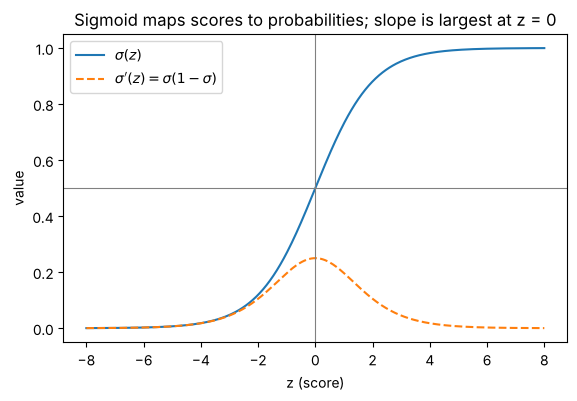

In [ ]:
zz = np.linspace(-8, 8, 400)
fig, ax = plt.subplots()
ax.plot(zz, sigmoid(zz), label=r"$\sigma(z)$")
ax.plot(zz, sigmoid(zz) * (1 - sigmoid(zz)), "--", label=r"$\sigma'(z)=\sigma(1-\sigma)$")
ax.axhline(0.5, color="gray", lw=0.8)
ax.axvline(0, color="gray", lw=0.8)
ax.set_xlabel("z (score)")
ax.set_ylabel("value")
ax.set_title("Sigmoid maps scores to probabilities; slope is largest at z = 0")
ax.legend()
plt.show()

**Interpretation.** The S-shaped curve is monotone increasing, so a higher score always means a higher probability. The dashed curve shows the slope is never larger than 0.25. This bounded slope is one reason gradient descent on logistic regression is well behaved.

## 2. Binary Classification Probabilities

For a label $y \in \{0,1\}$ and feature vector $\mathbf{x}$, logistic regression models
$$P(y=1\mid \mathbf{x}) = \sigma(\mathbf{w}^\top\mathbf{x} + b), \qquad P(y=0\mid\mathbf{x}) = 1-\sigma(\mathbf{w}^\top\mathbf{x}+b).$$

Taking the logit of both sides shows what is actually **linear** in this model, the log-odds:
$$\log\frac{P(y=1\mid\mathbf{x})}{P(y=0\mid\mathbf{x})} = \mathbf{w}^\top\mathbf{x} + b.$$

So each one-unit increase in feature $x_j$ adds $w_j$ to the log-odds, which **multiplies the odds by $e^{w_j}$**.

**Decision rule.** Predict class 1 when $P(y=1\mid\mathbf{x}) \ge 0.5$. Because $\sigma(z)\ge 0.5 \iff z \ge 0$, this is the same as $\mathbf{w}^\top\mathbf{x}+b \ge 0$. The **decision boundary** $\mathbf{w}^\top\mathbf{x}+b=0$ is therefore a line (in 2-D) or a hyperplane.

**Example (hand-picked parameters).** Suppose the chance a student passes an exam depends on hours studied $x$ with $w = 1.2$ and $b = -6$. The boundary is at $x = -b/w = 5$ hours.

In [ ]:
w_demo, b_demo = 1.2, -6.0
hours = np.array([0, 2, 4, 5, 6, 8, 10])
score = w_demo * hours + b_demo
p_pass = sigmoid(score)
odds = p_pass / (1 - p_pass)

print(f"{'hours':>5} {'score z':>8} {'P(pass)':>8} {'odds':>9} {'log-odds':>9} {'predict':>8}")
for h_, z_, p_, o_ in zip(hours, score, p_pass, odds):
    print(f"{h_:>5} {z_:>8.2f} {p_:>8.4f} {o_:>9.4f} {np.log(o_):>9.2f} {int(p_ >= 0.5):>8}")

print("\nOdds ratio for each extra hour: e^w =", round(np.exp(w_demo), 4))
print("Check: odds(6)/odds(5) =", round(odds[4] / odds[3], 4))

hours  score z  P(pass)      odds  log-odds  predict
    0    -6.00   0.0025    0.0025     -6.00        0
    2    -3.60   0.0266    0.0273     -3.60        0
    4    -1.20   0.2315    0.3012     -1.20        0
    5     0.00   0.5000    1.0000      0.00        1
    6     1.20   0.7685    3.3201      1.20        1
    8     3.60   0.9734   36.5982      3.60        1
   10     6.00   0.9975  403.4288      6.00        1

Odds ratio for each extra hour: e^w = 3.3201
Check: odds(6)/odds(5) = 3.3201


**Interpretation.**
- The **log-odds column equals the score column**, which confirms that the log-odds are linear in hours.
- At exactly 5 hours, $P(\text{pass})=0.5$: this is the decision boundary.
- Each extra hour multiplies the odds of passing by $e^{1.2}\approx 3.32$. The ratio odds(6)/odds(5) matches it exactly.
- Probabilities are **not** linear. Going from 4 to 5 hours raises $P$ by about 0.27, but going from 8 to 10 hours raises it by less than 0.03, because the sigmoid saturates.

### The Bernoulli likelihood
Each label is a Bernoulli random variable with success probability $p_i = \sigma(\mathbf{w}^\top\mathbf{x}_i+b)$, so
$$P(y_i\mid\mathbf{x}_i) = p_i^{\,y_i}(1-p_i)^{1-y_i}.$$
For independent data, the likelihood is the product $\prod_i p_i^{y_i}(1-p_i)^{1-y_i}$. Taking $-\log$ and averaging gives the **binary cross-entropy (negative log-likelihood) loss**:
$$\mathcal{L}(\mathbf{w},b) = -\frac1n\sum_{i=1}^n\Big[y_i\log p_i + (1-y_i)\log(1-p_i)\Big].$$
Below we compare two candidate parameter settings on the same small dataset. The better model has the higher likelihood, equivalently the lower loss.

In [ ]:
# Small dataset: hours studied and pass (1) / fail (0)
x_small = np.array([1, 2, 3, 4, 5, 6, 7, 8], dtype=float)
y_small = np.array([0, 0, 0, 1, 0, 1, 1, 1])

def bce(y, p, eps=1e-12):
    p = np.clip(p, eps, 1 - eps)
    return -np.mean(y * np.log(p) + (1 - y) * np.log(1 - p))

for name, (w_, b_) in {"Model A (w=1.2, b=-6)": (1.2, -6.0),
                       "Model B (w=0.3, b=-1)": (0.3, -1.0)}.items():
    p = sigmoid(w_ * x_small + b_)
    lik = np.prod(p**y_small * (1 - p)**(1 - y_small))
    print(f"{name}: likelihood = {lik:.5f},  cross-entropy = {bce(y_small, p):.4f}")

Model A (w=1.2, b=-6): likelihood = 0.07026,  cross-entropy = 0.3319
Model B (w=0.3, b=-1): likelihood = 0.01810,  cross-entropy = 0.5015


**Interpretation.** Model A gives a much higher likelihood and a lower cross-entropy, so it explains the observed passes and fails better. Maximizing likelihood and minimizing cross-entropy are the same goal, and Section 3 automates this search.

The plot below shows how cross-entropy penalizes a single prediction: confident wrong predictions are punished very heavily.

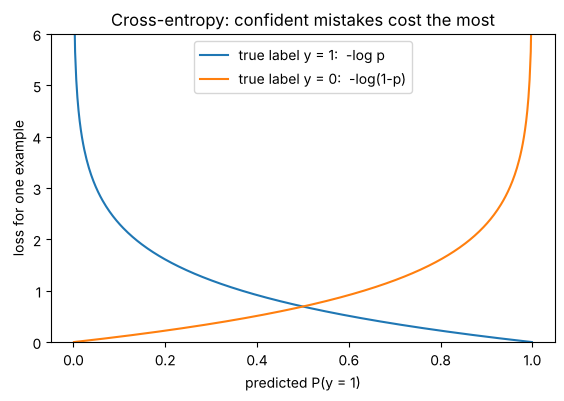

In [ ]:
p = np.linspace(0.001, 0.999, 400)
plt.plot(p, -np.log(p), label="true label y = 1:  -log p")
plt.plot(p, -np.log(1 - p), label="true label y = 0:  -log(1-p)")
plt.xlabel("predicted P(y = 1)")
plt.ylabel("loss for one example")
plt.title("Cross-entropy: confident mistakes cost the most")
plt.ylim(0, 6)
plt.legend()
plt.show()

**Interpretation.** If the true label is 1 and the model predicts $p=0.99$, the loss is about 0.01. If it predicts $p=0.01$, the loss is about 4.6. The loss grows without bound as a wrong prediction becomes more confident, which pushes the model toward calibrated probabilities.

## 3. Fitting Logistic Regression: Gradient, Hessian, Convexity, and Gradient Descent

To simplify notation, absorb the intercept into the weights: add a column of 1's to the data matrix $X\in\mathbb{R}^{n\times(d+1)}$ and let $\boldsymbol\theta = (b, w_1,\dots,w_d)$. Then $\mathbf{p} = \sigma(X\boldsymbol\theta)$, applied entrywise.

**Gradient.** Using $\sigma' = \sigma(1-\sigma)$, the derivative of the loss simplifies to
$$\nabla\mathcal{L}(\boldsymbol\theta) = \frac1n X^\top(\mathbf{p}-\mathbf{y}).$$
This has the same "prediction minus target" form as the least-squares gradient.

**Hessian.** Differentiating again,
$$\nabla^2\mathcal{L}(\boldsymbol\theta) = \frac1n X^\top S X, \qquad S = \operatorname{diag}\big(p_i(1-p_i)\big).$$
Since $p_i(1-p_i)>0$, for every vector $\mathbf{v}$ we have $\mathbf{v}^\top X^\top S X\mathbf{v} = \sum_i p_i(1-p_i)(\mathbf{x}_i^\top\mathbf{v})^2 \ge 0$. The Hessian is **positive semidefinite**, so the loss is **convex**: any local minimum is a global minimum, and gradient descent will not get stuck in a bad local minimum.

**Gradient descent.** Starting from $\boldsymbol\theta_0 = \mathbf 0$, repeat $\boldsymbol\theta_{k+1} = \boldsymbol\theta_k - \alpha\,\nabla\mathcal{L}(\boldsymbol\theta_k)$.

First we verify the gradient and Hessian formulas numerically.

In [ ]:
# A slightly larger "hours studied" dataset (deterministic)
hours_data = np.array([0.5, 1.0, 1.5, 2.0, 2.5, 3.0, 3.5, 4.0, 4.5, 5.0,
                       5.5, 6.0, 6.5, 7.0, 7.5, 8.0, 8.5, 9.0, 9.5, 10.0])
passed     = np.array([0,   0,   0,   0,   0,   0,   1,   0,   1,   0,
                       1,   0,   1,   1,   1,   1,   1,   1,   1,   1])

def add_intercept(X):
    X = np.atleast_2d(X)
    if X.shape[0] == 1:
        X = X.T
    return np.column_stack([np.ones(len(X)), X])

X1 = add_intercept(hours_data)          # shape (20, 2): [1, hours]

def loss(theta, X, y):
    return bce(y, sigmoid(X @ theta))

def grad(theta, X, y):
    return X.T @ (sigmoid(X @ theta) - y) / len(y)

def hessian(theta, X):
    p = sigmoid(X @ theta)
    return (X.T * (p * (1 - p))) @ X / len(X)

# Finite-difference check of the gradient at a random point
theta_test = rng.normal(size=2)
eps = 1e-6
fd_grad = np.array([(loss(theta_test + eps*e, X1, passed) - loss(theta_test - eps*e, X1, passed)) / (2*eps)
                    for e in np.eye(2)])
print("analytic gradient :", grad(theta_test, X1, passed))
print("finite-diff grad  :", fd_grad)
print("max difference    :", f"{np.max(np.abs(fd_grad - grad(theta_test, X1, passed))):.2e}")

# Convexity check: Hessian eigenvalues at several random points
for k in range(3):
    t = rng.normal(scale=2, size=2)
    print(f"Hessian eigenvalues at theta={t.round(2)}: {np.linalg.eigvalsh(hessian(t, X1))}")

analytic gradient : [0.429  1.2297]
finite-diff grad  : [0.429  1.2297]
max difference    : 5.42e-10
Hessian eigenvalues at theta=[ 1.33 -3.45]: [0.0013 0.0279]
Hessian eigenvalues at theta=[-0.48  1.9 ]: [0.0044 0.0573]
Hessian eigenvalues at theta=[-1.7  -0.63]: [0.0077 0.1493]


**Interpretation.** The analytic gradient agrees with the finite-difference approximation to about $10^{-9}$, confirming $\nabla\mathcal L = \tfrac1n X^\top(\mathbf p-\mathbf y)$. Every Hessian eigenvalue is positive at every point we tried, which is consistent with the proof that the loss is convex.

Now we run gradient descent from scratch.

In [ ]:
def fit_logistic_gd(X, y, lr=0.1, n_iter=20000, tol=1e-9):
    theta = np.zeros(X.shape[1])
    history = []
    for k in range(n_iter):
        g = grad(theta, X, y)
        theta -= lr * g
        if k % 50 == 0:
            history.append(loss(theta, X, y))
        if np.linalg.norm(g) < tol:
            break
    return theta, np.array(history), k + 1

theta_gd, hist, iters = fit_logistic_gd(X1, passed, lr=0.1)
b_gd, w_gd = theta_gd
print(f"Gradient descent finished after {iters} iterations")
print(f"intercept b = {b_gd:.4f},  slope w = {w_gd:.4f}")
print(f"final loss = {loss(theta_gd, X1, passed):.6f},  ||gradient|| = {np.linalg.norm(grad(theta_gd, X1, passed)):.2e}")

# Independent check with scikit-learn (essentially no regularization: huge C)
sk = LogisticRegression(C=1e12, max_iter=10000, tol=1e-10).fit(hours_data.reshape(-1, 1), passed)
print(f"\nscikit-learn:  b = {sk.intercept_[0]:.4f},  w = {sk.coef_[0,0]:.4f}")

Gradient descent finished after 17027 iterations
intercept b = -4.8646,  slope w = 1.0255
final loss = 0.311863,  ||gradient|| = 9.99e-10

scikit-learn:  b = -4.8646,  w = 1.0255


**Interpretation.** Our from-scratch gradient descent and scikit-learn reach the same parameters to about three or more decimal places. The gradient norm at the end is essentially zero, so we are at the minimum, and convexity guarantees it is the **global** minimum.

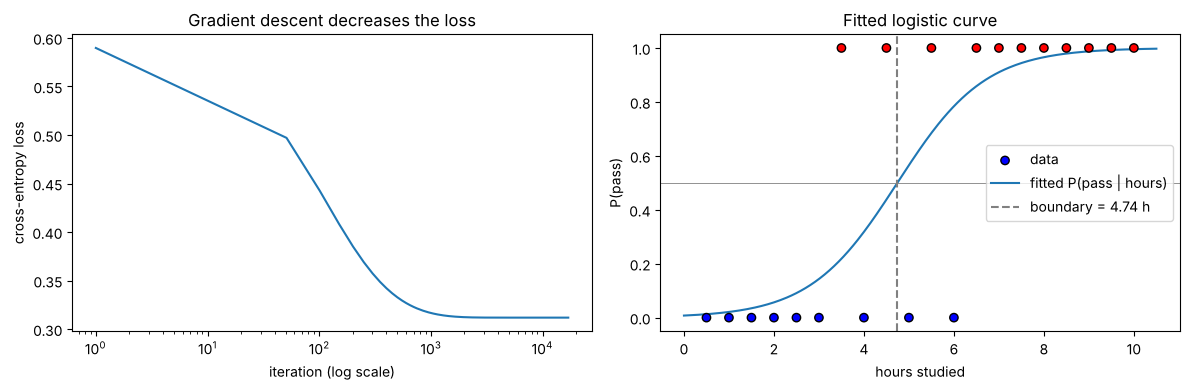

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(np.arange(len(hist)) * 50 + 1, hist)
axes[0].set_xscale("log")
axes[0].set_xlabel("iteration (log scale)")
axes[0].set_ylabel("cross-entropy loss")
axes[0].set_title("Gradient descent decreases the loss")

xs = np.linspace(0, 10.5, 300)
axes[1].scatter(hours_data, passed, c=passed, cmap="bwr", edgecolor="k", zorder=3, label="data")
axes[1].plot(xs, sigmoid(b_gd + w_gd * xs), label="fitted P(pass | hours)")
boundary = -b_gd / w_gd
axes[1].axvline(boundary, ls="--", color="gray", label=f"boundary = {boundary:.2f} h")
axes[1].axhline(0.5, color="gray", lw=0.6)
axes[1].set_xlabel("hours studied")
axes[1].set_ylabel("P(pass)")
axes[1].set_title("Fitted logistic curve")
axes[1].legend(loc="center right")
plt.tight_layout()
plt.show()

**Interpretation.** The loss falls quickly at first and then levels off as it approaches the minimum. In the right panel, the fitted S-curve passes through the region where passes and fails overlap (roughly 3.5–6.5 hours). That overlap is where the model is uncertain, and it is exactly where the curve is steepest.

## 4. Interpreting the Fitted Model

Three ways to read the fitted parameters:
1. **Decision boundary:** $x^{\ast} = -b/w$ is the number of hours at which $P(\text{pass}) = 0.5$.
2. **Odds ratio:** $e^{w}$ is the factor by which the odds of passing are multiplied for each extra hour.
3. **Predicted probabilities** for new students.

In [ ]:
print(f"Decision boundary: {-b_gd / w_gd:.2f} hours  (P(pass) = 0.5 there)")
print(f"Odds ratio per extra hour: e^w = {np.exp(w_gd):.3f}")
for h_new in [2, 4, 5, 6, 9]:
    p = sigmoid(b_gd + w_gd * h_new)
    print(f"  {h_new} hours -> P(pass) = {p:.3f}  -> predict {'PASS' if p >= 0.5 else 'FAIL'}")

pred = (sigmoid(X1 @ theta_gd) >= 0.5).astype(int)
print(f"\nTraining accuracy: {accuracy_score(passed, pred):.2f}")
print("Confusion matrix [[TN, FP], [FN, TP]]:\n", confusion_matrix(passed, pred))

Decision boundary: 4.74 hours  (P(pass) = 0.5 there)
Odds ratio per extra hour: e^w = 2.788
  2 hours -> P(pass) = 0.057  -> predict FAIL
  4 hours -> P(pass) = 0.318  -> predict FAIL
  5 hours -> P(pass) = 0.565  -> predict PASS
  6 hours -> P(pass) = 0.784  -> predict PASS
  9 hours -> P(pass) = 0.987  -> predict PASS

Training accuracy: 0.80
Confusion matrix [[TN, FP], [FN, TP]]:
 [[7 2]
 [2 9]]


**Interpretation.** Each extra hour of study multiplies the odds of passing by the printed odds ratio. The model is not perfect: the confusion matrix shows a few misclassified students in the overlap region. That is expected, because logistic regression outputs **probabilities**, and a probability of 0.6 means about 4 in 10 such students would still fail.

### 4.1 Two features: a linear decision boundary

With two features, $P(y=1\mid\mathbf x) = \sigma(b + w_1x_1 + w_2x_2)$, and the boundary $b + w_1x_1 + w_2x_2 = 0$ is a **straight line**:
$$x_2 = -\frac{b + w_1 x_1}{w_2}.$$
We generate two overlapping Gaussian clouds, fit with our own gradient descent, and draw the boundary and the probability surface.

In [ ]:
n_per = 60
class0 = rng.multivariate_normal([-1.0, -0.5], [[1.0, 0.3], [0.3, 1.0]], n_per)
class1 = rng.multivariate_normal([1.5,  1.0], [[1.0, -0.2], [-0.2, 1.0]], n_per)
X2 = np.vstack([class0, class1])
y2 = np.r_[np.zeros(n_per), np.ones(n_per)].astype(int)

X2i = add_intercept(X2)
theta2, hist2, it2 = fit_logistic_gd(X2i, y2, lr=0.5, n_iter=20000)
b2, w21, w22 = theta2
sk2 = LogisticRegression(C=1e12, max_iter=10000, tol=1e-10).fit(X2, y2)

print(f"GD:      b = {b2:.4f}, w1 = {w21:.4f}, w2 = {w22:.4f}  ({it2} iterations)")
print(f"sklearn: b = {sk2.intercept_[0]:.4f}, w1 = {sk2.coef_[0,0]:.4f}, w2 = {sk2.coef_[0,1]:.4f}")
pred2 = (sigmoid(X2i @ theta2) >= 0.5).astype(int)
print(f"Training accuracy: {accuracy_score(y2, pred2):.3f}")
print("Confusion matrix:\n", confusion_matrix(y2, pred2))

GD:      b = -1.5217, w1 = 3.6914, w2 = 1.0981  (3867 iterations)
sklearn: b = -1.5217, w1 = 3.6914, w2 = 1.0981
Training accuracy: 0.958
Confusion matrix:
 [[58  2]
 [ 3 57]]


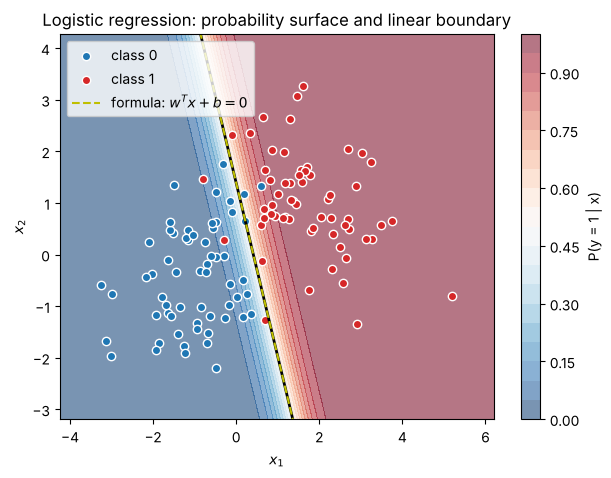

In [ ]:
gx, gy = np.meshgrid(np.linspace(X2[:,0].min()-1, X2[:,0].max()+1, 200),
                     np.linspace(X2[:,1].min()-1, X2[:,1].max()+1, 200))
grid = add_intercept(np.c_[gx.ravel(), gy.ravel()])
P = sigmoid(grid @ theta2).reshape(gx.shape)

fig, ax = plt.subplots(figsize=(7, 5))
cf = ax.contourf(gx, gy, P, levels=20, cmap="RdBu_r", alpha=0.55)
plt.colorbar(cf, label="P(y = 1 | x)")
ax.contour(gx, gy, P, levels=[0.5], colors="k", linewidths=2)
ax.scatter(*class0.T, c="tab:blue", edgecolor="w", label="class 0")
ax.scatter(*class1.T, c="tab:red", edgecolor="w", label="class 1")
x1_line = np.linspace(gx.min(), gx.max(), 2)
ax.plot(x1_line, -(b2 + w21 * x1_line) / w22, "y--", lw=1.5, label="formula: $w^T x + b = 0$")
ax.set_xlim(gx.min(), gx.max()); ax.set_ylim(gy.min(), gy.max())
ax.set_xlabel("$x_1$"); ax.set_ylabel("$x_2$")
ax.set_title("Logistic regression: probability surface and linear boundary")
ax.legend(loc="upper left")
plt.show()

**Interpretation.** The black $P=0.5$ contour lies exactly on the yellow dashed line computed from the formula $x_2 = -(b+w_1x_1)/w_2$, which confirms that the boundary is linear. Probability changes smoothly across the boundary instead of jumping, and the weight vector $(w_1,w_2)$ points in the direction in which $P(y=1)$ increases fastest. Our gradient-descent coefficients again match scikit-learn.

## 5. A Caveat: Perfectly Separable Data and Regularization

If a line separates the two classes **perfectly**, the loss can be pushed arbitrarily close to 0 by scaling $\mathbf w$ up, because that makes every $p_i \to y_i$. The minimum is never reached, so **the maximum-likelihood estimate does not exist** and the weights grow without bound during gradient descent.

Adding an $L_2$ penalty fixes this:
$$\mathcal L_\lambda(\boldsymbol\theta) = \mathcal L(\boldsymbol\theta) + \frac{\lambda}{2}\lVert \mathbf w\rVert^2,$$
which adds $\lambda\mathbf w$ to the gradient and $\lambda$ to the Hessian's diagonal entries for the weights (the intercept $b$ is not penalized). The penalty grows without bound as $\lVert\mathbf w\rVert\to\infty$, so the weights can no longer run off to infinity, and the regularized loss has a finite minimizer.

In [ ]:
x_sep = np.array([1, 2, 3, 4, 6, 7, 8, 9], dtype=float)
y_sep = np.array([0, 0, 0, 0, 1, 1, 1, 1])
Xs = add_intercept(x_sep)

def run(lam, n_iter):
    theta = np.zeros(2)
    for _ in range(n_iter):
        g = grad(theta, Xs, y_sep)
        g[1:] += lam * theta[1:]        # do not penalize the intercept
        theta -= 0.5 * g
    return theta

print(f"{'iterations':>10} | {'w (no penalty)':>15} {'loss':>10} | {'w (lambda=0.01)':>16}")
for n in [100, 1000, 10000, 100000]:
    t0 = run(0.0, n); t1 = run(0.01, n)
    print(f"{n:>10} | {t0[1]:>15.3f} {loss(t0, Xs, y_sep):>10.2e} | {t1[1]:>16.3f}")

iterations |  w (no penalty)       loss |  w (lambda=0.01)
       100 |           0.933   1.48e-01 |            0.923
      1000 |           2.143   3.24e-02 |            1.952


     10000 |           4.001   4.71e-03 |            2.438


    100000 |           6.210   5.12e-04 |            2.439


**Interpretation.** Without a penalty, the slope keeps growing as we run more iterations while the loss creeps toward 0. The curve is turning into a step function, and its probabilities become overconfident. With a small $L_2$ penalty ($\lambda = 0.01$), the slope converges to a finite value, so the regularized problem has a unique, stable solution. This is why libraries such as scikit-learn regularize by default.